<a href="https://colab.research.google.com/github/Raul-DAW/Google-Share-Optativa/blob/main/Ra%C3%BAl_practica_aws.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install boto3

In [5]:
import boto3, cv2, numpy as np, os
from dotenv import load_dotenv
from PIL import Image
from google.colab.patches import cv2_imshow

Pongo mis credenciales de AWS

In [6]:
%%writefile .env
aws_access_key_id=A....RX
aws_secret_access_key=en....q
aws_session_token=IQo.....//JQ==
aws_region=us-east-1
aws_bucket=loserfruit

Overwriting .env


In [7]:
load_dotenv()

aws_access_key_id = os.environ.get('aws_access_key_id')
aws_secret_access_key = os.environ.get('aws_secret_access_key')
aws_session_token = os.environ.get('aws_session_token')
aws_bucket = os.environ.get('aws_bucket')
aws_region = os.environ.get('aws_region')

In [8]:
session = boto3.Session(
        aws_access_key_id = aws_access_key_id,
        aws_secret_access_key = aws_secret_access_key,
        aws_session_token = aws_session_token,
        region_name = aws_region)
s3 = session.resource('s3')
rekognition = session.client('rekognition')

In [9]:
file = 'grupo_emociones.jpg'
key = 'grupo_emociones.jpg'
try:
  s3.Object(aws_bucket, key).upload_file(file)
except Exception as e:
  print(e)

In [10]:
try:
  response = rekognition.detect_faces(Image={'S3Object': {'Bucket': aws_bucket, 'Name': key}}, Attributes=['ALL'])
except Exception as e:
  print(e)

In [12]:
response

{'FaceDetails': [{'BoundingBox': {'Width': 0.15072105824947357,
    'Height': 0.3135753571987152,
    'Left': 0.19144947826862335,
    'Top': 0.3314415216445923},
   'AgeRange': {'Low': 24, 'High': 30},
   'Smile': {'Value': True, 'Confidence': 99.7476806640625},
   'Eyeglasses': {'Value': False, 'Confidence': 99.99990844726562},
   'Sunglasses': {'Value': False, 'Confidence': 99.99998474121094},
   'Gender': {'Value': 'Male', 'Confidence': 99.11290740966797},
   'Beard': {'Value': True, 'Confidence': 99.79436492919922},
   'Mustache': {'Value': False, 'Confidence': 57.03867721557617},
   'EyesOpen': {'Value': False, 'Confidence': 98.97315216064453},
   'MouthOpen': {'Value': False, 'Confidence': 87.19258117675781},
   'Emotions': [{'Type': 'HAPPY', 'Confidence': 100.0},
    {'Type': 'CALM', 'Confidence': 0.007140636444091797},
    {'Type': 'SURPRISED', 'Confidence': 0.0009164214134216309},
    {'Type': 'CONFUSED', 'Confidence': 0.0008443991537205875},
    {'Type': 'DISGUSTED', 'Confid

In [13]:
img = Image.open(file)
#img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2RGBA)
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGRA)

height, width, _ = img_cv2.shape

for faceDetail in response['FaceDetails']:
  box = faceDetail['BoundingBox']
  x = int(width * box['Left'])
  y = int(height * box['Top'])
  w = int(width * box['Width'])
  h = int(height * box['Height'])
  roi = img_cv2[y:y+h, x:x+w]
  roi = cv2.GaussianBlur(roi, (83, 83), 30)
  img_cv2[y:y+roi.shape[0], x:x+roi.shape[1]] = roi
cv2.imwrite('faces_blur.jpg', img_cv2)

True

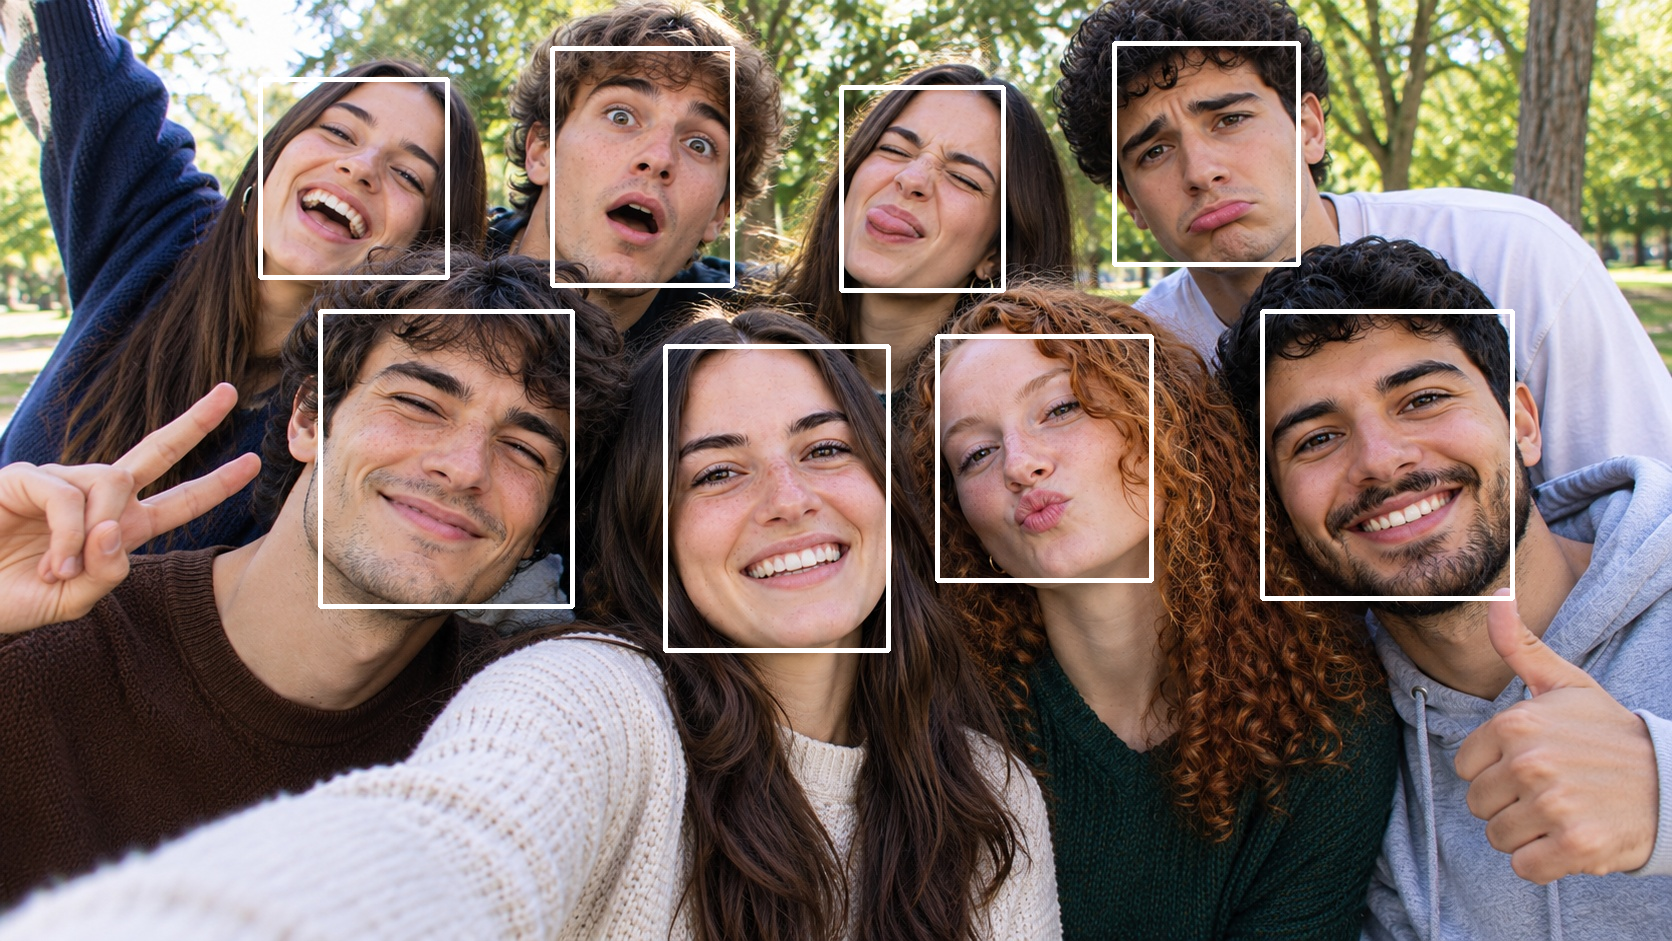

In [14]:
img = Image.open(file)
#img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2RGBA)
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGRA)

height, width, _ = img_cv2.shape

for faceDetail in response['FaceDetails']:
  box = faceDetail['BoundingBox']
  x = int(width * box['Left'])
  y = int(height * box['Top'])
  w = int(width * box['Width'])
  h = int(height * box['Height'])
  cv2.rectangle(img_cv2, (x, y), (x + w, y + h), (0, 255, 0), 3)
cv2.imwrite('faces_rect.jpg', img_cv2)
cv2_imshow(img_cv2)

# Ejercicios

1. Desarrolla un script que detecte personas en una fotografía y genere un informe con los resultados que puedas extraer. En este caso, se obtiene más información que en la práctica anterior.

2. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se aplique un efecto de desenfoque (blur) a toda la imagen, manteniendo los rostros detectados nítidos y sin desenfocar. La idea es utilizar cv2.GaussianBlur() para desenfocar la imagen completa y, después, copiar sobre ella las regiones faciales de la imagen original utilizando las coordenadas que devuelve Rekognition.

3. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se detecten y recorten todos los rostros de una fotografía y se genere un collage que contenga únicamente los rostros detectados.
Requisitos:
    Detectar los rostros de la imagen mediante Amazon Rekognition.
    Recortar cada rostro utilizando las coordenadas devueltas por el servicio.
    Redimensionar los recortes para que tengan unas dimensiones uniformes.
    Organizar los rostros en una cuadrícula y generar una única imagen con todos ellos.
    Mostrar y guardar el collage resultante.
Ampliación: modifica el número de filas y columnas del collage y comprueba el resultado con fotografías que contengan diferentes cantidades de rostros.

In [21]:
# ejercicio 1
# Obtenemos los rostros detectados por Amazon Rekognition
rostros = response['FaceDetails']

print("INFORME DE LA FOTOGRAFÍA")
print("--------------------------")

# Muestra el número de rostros
print("Número de rostros detectados:", len(rostros))

# Recorremos cada rostro para mostrar su información
for i, rostro in enumerate(rostros):

    print()
    print("PERSONA", i + 1)
    print("--------------------------")

    confianza = rostro['Confidence']
    print("Confianza:", round(confianza, 2), "%")

    edad = rostro['AgeRange']
    print("Posible Edad:", edad['Low'], "-", edad['High'], "años")

    # Género
    genero = rostro['Gender']
    print("Género:", genero['Value'])
    print("Confianza del género:", round(genero['Confidence'], 2), "%")

    sonrisa = rostro['Smile']['Value']

    if sonrisa:
        print("Sonriendo: Sí")
    else:
        print("Sonriendo: No")

    emociones = rostro['Emotions']

    if emociones:
        emocion = max(emociones, key=lambda e: e['Confidence'])
        print("Emoción:", emocion['Type'])
        print("Confianza de la emoción:", round(emocion['Confidence'], 2), "%")

print()
print("FIN DEL INFORME")

INFORME DE LA FOTOGRAFÍA
--------------------------
Número de rostros detectados: 8

PERSONA 1
--------------------------
Confianza: 100.0 %
Posible Edad: 24 - 30 años
Género: Male
Confianza del género: 99.11 %
Sonriendo: Sí
Emoción: HAPPY
Confianza de la emoción: 100.0 %

PERSONA 2
--------------------------
Confianza: 100.0 %
Posible Edad: 21 - 27 años
Género: Male
Confianza del género: 96.36 %
Sonriendo: Sí
Emoción: HAPPY
Confianza de la emoción: 100.0 %

PERSONA 3
--------------------------
Confianza: 100.0 %
Posible Edad: 21 - 27 años
Género: Female
Confianza del género: 99.8 %
Sonriendo: Sí
Emoción: HAPPY
Confianza de la emoción: 100.0 %

PERSONA 4
--------------------------
Confianza: 100.0 %
Posible Edad: 24 - 30 años
Género: Female
Confianza del género: 99.96 %
Sonriendo: No
Emoción: HAPPY
Confianza de la emoción: 93.33 %

PERSONA 5
--------------------------
Confianza: 100.0 %
Posible Edad: 22 - 28 años
Género: Male
Confianza del género: 98.5 %
Sonriendo: No
Emoción: SURPRISE

En este ejercicio se utiliza Amazon Rekognition para analizar una fotografía y obtener información sobre los rostros detectados. El programa fue capaz de detectar 8 caras en la fotografía escogida y tras detectar las caras, el programa es capaz de estimar diferentes datos como la expresion de la persona, el genero o la confianza del resultado


Estos resultados muestran cómo una inteligencia artificial puede analizar los rostros de una fotografía, aunque algunos datos, como la edad y las emociones, son aproximaciones y pueden no ser exactos.

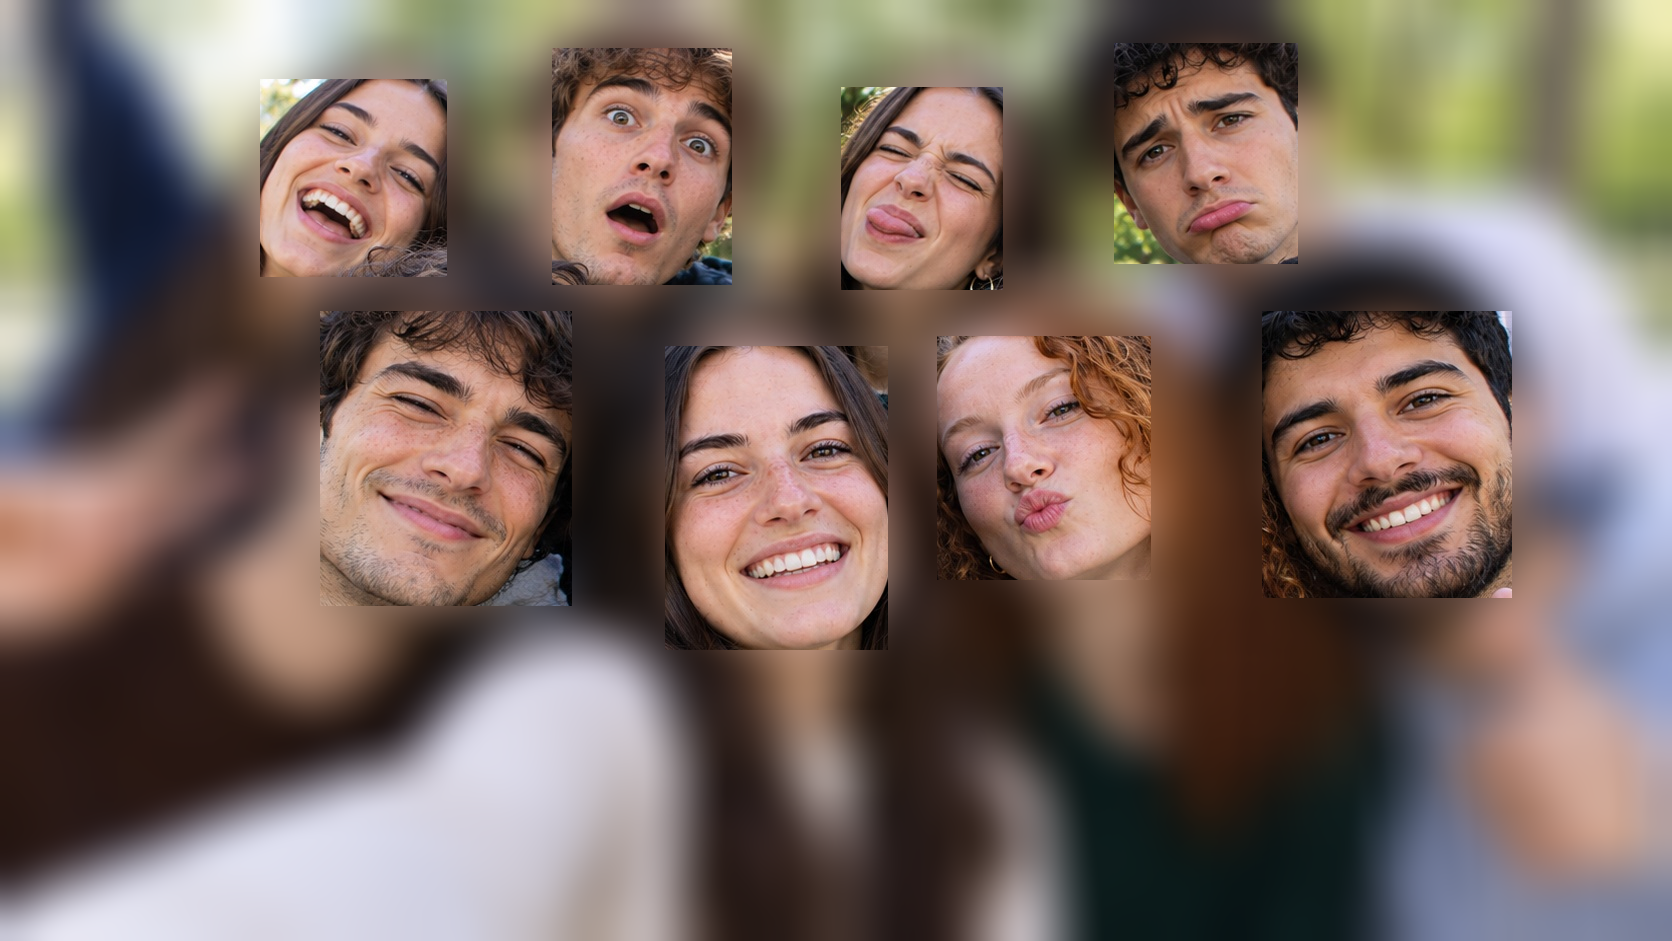

In [17]:
# ejercicio 2
# Se abre la imagen original y se desenfoca
img = Image.open(file).convert("RGB")
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
imagen_blur = cv2.GaussianBlur(img_cv2, (83, 83), 30)
height, width, _ = img_cv2.shape

# Se recorre cada rostro y se calcula la posición de la cara
for rostro in response["FaceDetails"]:

    box = rostro["BoundingBox"]
    x = int(width * box["Left"])
    y = int(height * box["Top"])
    w = int(width * box["Width"])
    h = int(height * box["Height"])

    # Se establecen limites de la imagen
    x1 = max(0, x)
    y1 = max(0, y)
    x2 = min(width, x + w)
    y2 = min(height, y + h)

    # Recuperamos la cara original sin desenfocar
    imagen_blur[y1:y2, x1:x2] = img_cv2[y1:y2, x1:x2]

# Se guarda la iamgen y se muestra el resultado
cv2.imwrite("rostros_nitidos.jpg", imagen_blur)
cv2_imshow(imagen_blur)


En este ejercicio se utiliza Amazon Rekognition para localizar los rostros de una fotografía y OpenCV para aplicar un desenfoque.Para poder hacerlo se  desenfoca toda la imagen y después se utilizan las coordenadas de los cuatro rostros detectados para recuperar las caras originales sin desenfocar.
El resultado de esto es una fotografía en la que las cuatro caras aparecen nítidas, mientras que el resto de la imagen está desenfocado. Cabe recalcar que la forma rectangular que muestra el rostro es debido a que el programa corto correctamente la fotografía original

Número de rostros en el collage: 8


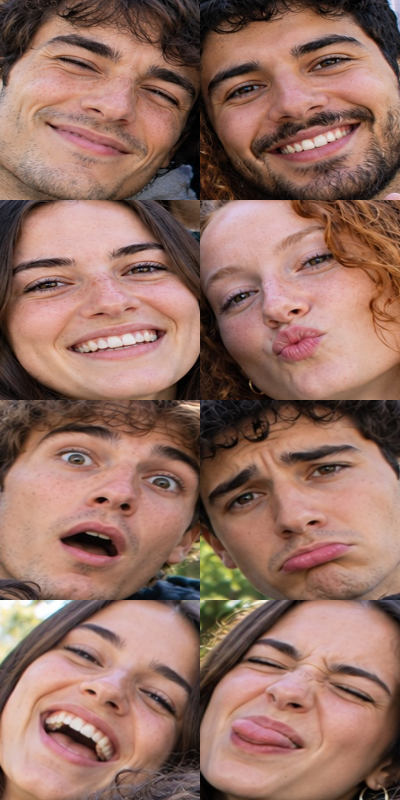

In [19]:
# ejercicio 3
imagen = cv2.imread("grupo_emociones.jpg")
alto, ancho, _ = imagen.shape

#  lista para guardar las caras
rostros_recortados = []

# Recorre los rostros detectados
for rostro in response["FaceDetails"]:

    # Coordeanads de cada rostro
    caja = rostro["BoundingBox"]

    x = int(caja["Left"] * ancho)
    y = int(caja["Top"] * alto)
    w = int(caja["Width"] * ancho)
    h = int(caja["Height"] * alto)

    # Evitamos que las coordenadas salgan de la imagen
    x1 = max(0, x)
    y1 = max(0, y)
    x2 = min(ancho, x + w)
    y2 = min(alto, y + h)


    cara = imagen[y1:y2, x1:x2]
    # Se ponen todas las caras del mismo tamaño y las guardamos en la lista previamente creada
    cara = cv2.resize(cara, (200, 200))

    # Guardamos la cara en la lista
    rostros_recortados.append(cara)
columnas = 2

# Calcula las filas necesarias
filas = int(np.ceil(len(rostros_recortados) / columnas))

# Cea una imagen blanca donde se colocarán las caras
collage = np.ones(
    (filas * 200, columnas * 200, 3),
    dtype=np.uint8
) * 255

# Coloco cada cara en su posición
for i, cara in enumerate(rostros_recortados):

    fila = i // columnas
    columna = i % columnas

    y = fila * 200
    x = columna * 200

    collage[y:y+200, x:x+200] = cara

# Se guarda el collage y se muestra
cv2.imwrite("collage_rostros.jpg", collage)
print("Número de rostros en el collage:", len(rostros_recortados))

cv2_imshow(collage)

En este ejercicio se utiliza Amazon Rekognition para localizar los rostros de una fotografía y OpenCV para recortarlos y crear un collage. Para hacer este ejercicio, se deben de obtener primero las coordenadas de todas las caras de la foto y después se recorta cada una. Después, todos los recortes se ajustan al mismo tamaño de 200 × 200 píxeles para después colocar las 4 caras en una cuadrícula de dos filas y dos columnas, formando una única imagen.

El resultado es un collage con los cuatro rostros detectados, todos con el mismo tamaño y organizados correctamente.